# 3g. Predict elective demand using a list of planned admissions

In notebook 3e I predicted demand from patients yet to arrive using past arrival rates alone. For elective admissions, that approach treats the number of patients who will come in today as uncertain. In practice, hospitals often know a good deal more than that. Planned admissions are recorded on a list some hours before the patients arrive, for example on a 'To Come In' (TCI) list, or as pending admission requests raised the afternoon before.

When a list like this is available, most of the uncertainty about how many electives will arrive is already resolved. What remains is:

* **Attrition.** Some listed patients do not arrive. They cancel, do not attend, are deferred to another day, or arrive at a different service from the one they were listed under. Others arrive but do not need a bed, for example day cases who go home the same day.
* **Timing.** A listed patient who does arrive may do so before or after the prediction window.
* **Unlisted electives.** Some elective patients are never on the list.

In this notebook I show how to use the `ListBasedAdmissionPredictor` class to condition the prediction on the list. The predicted count has two independent parts:

* **Listed patients still to arrive.** Each pending patient arrives in the window with probability `q`, or does not, so the number arriving is binomial. (In general this is a Poisson-binomial, because `q` could differ between patients. In this version `q` is estimated per service, so within a service it is a plain binomial.)
* **Off-list arrivals.** Electives who were not on that day's list for that service are modelled with a Poisson distribution, as in notebook 3e. I call these *off-list* electives. They include patients who were never listed, and also patients who were listed for another day or under another service.

The two distributions are convolved to give the prediction.

A note on identifiers. In notebook 3e I said that the hospital visit for an elective procedure may not be recorded in data before the patient arrives. Where a list of planned admissions exists, the visit identifier (here called `encounter`) is often created when the patient is listed, before they arrive. That is what makes it possible to match the list to later arrivals, and to drop listed patients from the list once they have arrived.

In [1]:
# Reload functions every time
%load_ext autoreload
%autoreload 2

## Generate fake data

I use the `create_fake_elective_lists` function to generate three months of fake data, from January to March 2023, for three services:

* `surgical` has a large list on weekdays and a small one at weekends.
* `paediatric` has a very short list, too short to estimate list probabilities reliably.
* `haem/onc` has no list at all. All its electives are unlisted.

Each listed patient has one outcome. They arrive at the listed service on the day, arrive at a different service on the day, arrive the evening before, are deferred to the next day, or do not arrive. With `not_admitted_share=0.3`, 30% of those who arrive at the listed service on the day do not need a bed. Unlisted electives also arrive at every service.

The function returns two dataframes. `elective_arrivals` has one row per elective arrival, with `is_admitted` set to `False` for listed patients who arrived without needing a bed. `elective_list` has one row per listed patient with the date they were booked for.

In [2]:
from patientflow.generate import create_fake_elective_lists

elective_arrivals, elective_list = create_fake_elective_lists(
    '2023-01-01', '2023-04-01', not_admitted_share=0.3
)
elective_arrivals.head()

,arrival_datetime,encounter,service,is_admitted
0,2023-01-01 10:26:27,E0000003,haem/onc,True
1,2023-01-01 11:27:47,E0000014,surgical,True
2,2023-01-01 11:46:50,E0000013,surgical,True
3,2023-01-01 12:03:04,E0000001,haem/onc,True
4,2023-01-01 12:56:58,E0000002,haem/onc,True


In [3]:
elective_list.head()

,encounter,service,intended_date
0,E0000020,surgical,2023-01-02
1,E0000021,surgical,2023-01-02
2,E0000022,surgical,2023-01-02
3,E0000023,surgical,2023-01-02
4,E0000024,surgical,2023-01-02


The table below shows what happened to the listed patients. Most arrive at the listed service on the day they were booked for, but some of those do not need a bed, and a substantial minority do not arrive at the listed service that day at all.

In [4]:
import numpy as np
import pandas as pd

# Match each listed patient to their arrival, if any
listed_outcomes = elective_list.merge(
    elective_arrivals, on='encounter', how='left', suffixes=('_listed', '_arrived')
)
arrival_date = listed_outcomes['arrival_datetime'].dt.date

listed_outcomes['outcome'] = np.select(
    [
        listed_outcomes['arrival_datetime'].isna(),
        arrival_date < listed_outcomes['intended_date'],
        arrival_date > listed_outcomes['intended_date'],
        listed_outcomes['service_arrived'] != listed_outcomes['service_listed'],
        listed_outcomes['is_admitted'].eq(False),
    ],
    [
        'did not arrive',
        'arrived the evening before',
        'arrived on a later day',
        'arrived at a different service',
        'arrived without needing a bed',
    ],
    default='arrived at the listed service on the day',
)

listed_outcomes.groupby('service_listed')['outcome'].value_counts(normalize=True).unstack(fill_value=0).round(2)

outcome,arrived at a different service,arrived at the listed service on the day,arrived on a later day,arrived the evening before,arrived without needing a bed,did not arrive
service_listed,,,,,,
paediatric,0.08,0.54,0.12,0.00,0.19,0.08
surgical,0.05,0.49,0.04,0.05,0.22,0.15


## Split into training and test periods

I use January and February for training, and March for testing. As in notebook 3e, the test period starts on 1 March 2023.

The list for the first day of the training period is left out. Some patients on that list arrived the evening before, which falls outside the training period, so they would look as if they never arrived. Starting the list one day in avoids that.

The training arrivals are split in two. Arrivals that needed a bed give the arrival rates and the probabilities of arriving at each service. Listed patients who arrived without needing a bed are only used to tell the model when they stopped being pending.

In [5]:
from datetime import date

start_training_set = date(2023, 1, 1)
start_test_set = date(2023, 3, 1)
num_days = (start_test_set - start_training_set).days

arrival_dates = elective_arrivals['arrival_datetime'].dt.date
train_period_arrivals = elective_arrivals[
    (arrival_dates >= start_training_set) & (arrival_dates < start_test_set)
]
train_elective_arrivals = train_period_arrivals[train_period_arrivals['is_admitted']]
train_arrivals_not_admitted = train_period_arrivals[~train_period_arrivals['is_admitted']]

# Leave out the list for the first training day (see above)
train_elective_list = elective_list[
    (elective_list['intended_date'] > start_training_set)
    & (elective_list['intended_date'] < start_test_set)
]

print(f'Training arrivals: {len(train_elective_arrivals)} needing a bed, '
      f'{len(train_arrivals_not_admitted)} not; '
      f'training list rows: {len(train_elective_list)}; days: {num_days}')

Training arrivals: 1039 needing a bed, 174 not; training list rows: 864; days: 59


## Fit the model

`ListBasedAdmissionPredictor` is a subclass of `DirectAdmissionPredictor`, which predicts arrivals with a Poisson distribution based on past arrival rates, like the first approach in notebook 3e. It is fitted in the same way, with two differences: the list is passed as `list_df`, and listed patients who arrived without needing a bed are passed as `arrivals_not_admitted`.

Three things to note about the inputs:

* `train_df` must contain only elective arrivals that needed a bed, because it also sets the arrival rates.
* `train_df` must contain those arrivals at **all** services, not a slice for one service. The model needs to see listed patients who arrived at a different service.
* The columns used in `filters` (here `service`) must be present in both `train_df` and `list_df`, so that listed patients can be assigned to services. `arrivals_not_admitted` only needs `encounter`.

Why pass patients who did not need a bed at all? At inference time, the model drops every listed patient who has already arrived, because nobody knows yet which of them will need a bed. Training and inference must agree on who is still pending, so training has to see the same arrivals. For the same reason, `arrivals_not_admitted` at fit and the `arrivals` passed at inference time should define "did not need a bed" in the same way. The conditioning section below shows what goes wrong if they disagree.

At fit time, the model learns, for each service and each 15-minute interval of the day:

* `p_k`, the probability that a listed patient arrives at the listed service in that interval and needs a bed. It is stored as `list_interval_probs`.
* `r_k`, the probability that a listed patient arrives at a different service in that interval and needs a bed. It is stored as `list_other_service_probs`.
* `s_k`, the probability that a listed patient arrives in that interval but does not need a bed. It is stored as `list_not_admitted_probs`.
* Arrival rates for off-list electives (the *off-list rates*).

It also keeps the usual arrival rates for all electives (the *all-elective rates*), so that it behaves exactly like `DirectAdmissionPredictor` when no list is supplied.

A service needs at least `min_list_count` listed patients (50 by default) for its list probabilities to be used. Below that, it falls back to the Poisson result. The model warns about services that had some listed patients but too few.

In [6]:
import warnings
from datetime import timedelta
from patientflow.predictors.list_based_admission_predictor import ListBasedAdmissionPredictor

services = ['surgical', 'paediatric', 'haem/onc']
filters = {service: {'service': service} for service in services}

yta_time_interval = timedelta(minutes=15)

list_model = ListBasedAdmissionPredictor(filters=filters)
with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter('always')
    list_model.fit(
        train_elective_arrivals.set_index('arrival_datetime'),
        list_df=train_elective_list,
        arrivals_not_admitted=train_arrivals_not_admitted.set_index('arrival_datetime'),
        yta_time_interval=yta_time_interval,
        num_days=num_days,
    )
for warning in caught:
    print(f'Warning: {warning.message}')

The table below summarises what was learned for each service. `list_count` is the number of listed patients in the denominator of `p_k`, `r_k` and `s_k`. Summing `p_k` over the day gives the share of listed patients who arrived at the listed service on the day and needed a bed. Summing `r_k` gives the share who arrived at a different service and needed a bed, and summing `s_k` the share who arrived without needing a bed.

In [7]:
share = 'Share of listed patients arriving on the day'
rows = {}
for service in services:
    service_weights = list_model.weights[service]
    uses_list = list_model.uses_list(service)
    rows[service] = {
        ('', 'list_count'): service_weights['list_count'],
        ('', 'uses list'): uses_list,
        (share, 'needed a bed, listed service (p_k)'): service_weights['list_interval_probs'].sum() if uses_list else None,
        (share, 'needed a bed, other service (r_k)'): service_weights['list_other_service_probs'].sum() if uses_list else None,
        (share, 'did not need a bed (s_k)'): service_weights['list_not_admitted_probs'].sum() if uses_list else None,
    }
pd.DataFrame.from_dict(rows, orient='index').rename_axis('service').round(3)

Share of listed patients arriving on the day  \
           list_count uses list           needed a bed, listed service (p_k)   
service                                                                        
surgical          804      True                                        0.519   
paediatric         17     False                                          NaN   
haem/onc            0     False                                          NaN   

                                                                       
           needed a bed, other service (r_k) did not need a bed (s_k)  
service                                                                
surgical                               0.052                    0.213  
paediatric                               NaN                      NaN  
haem/onc                                 NaN                      NaN

`haem/onc` had no listed patients, so it falls back to Poisson without a warning. `paediatric` had some, but fewer than `min_list_count`, so it falls back with the warning shown above.

### When do listed patients arrive?

The chart below shows `p_k`, `r_k` and `s_k` for the surgical list, summed to hourly values. The first two are patients who needed a bed, split by where they arrived. The third is patients who did not need a bed, at any service. Listed patients arrive mainly in the morning.

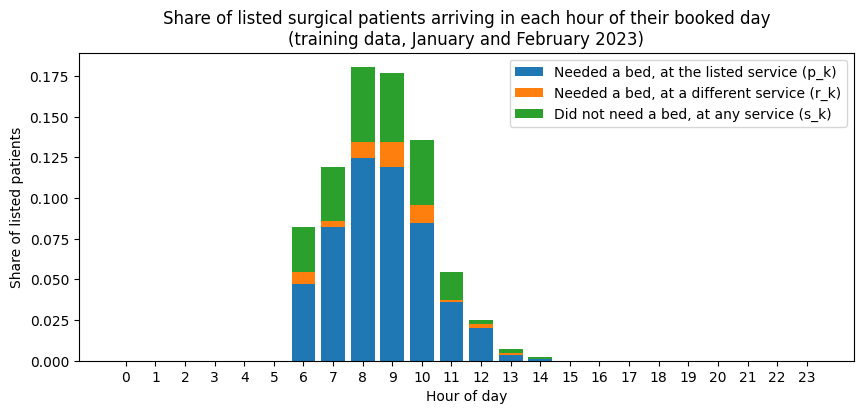

In [8]:
import matplotlib.pyplot as plt

intervals_per_hour = int(timedelta(hours=1) / yta_time_interval)
surgical_weights = list_model.weights['surgical']

# Sum the 15-minute values to hourly values
same_service_by_hour = surgical_weights['list_interval_probs'].reshape(24, intervals_per_hour).sum(axis=1)
other_service_by_hour = surgical_weights['list_other_service_probs'].reshape(24, intervals_per_hour).sum(axis=1)
not_admitted_by_hour = surgical_weights['list_not_admitted_probs'].reshape(24, intervals_per_hour).sum(axis=1)

fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(range(24), same_service_by_hour, label='Needed a bed, at the listed service (p_k)')
ax.bar(range(24), other_service_by_hour, bottom=same_service_by_hour, label='Needed a bed, at a different service (r_k)')
ax.bar(range(24), not_admitted_by_hour, bottom=same_service_by_hour + other_service_by_hour,
       label='Did not need a bed, at any service (s_k)')
ax.set_xticks(range(24))
ax.set_xlabel('Hour of day')
ax.set_ylabel('Share of listed patients')
ax.set_title('Share of listed surgical patients arriving in each hour of their booked day\n'
             '(training data, January and February 2023)')
ax.legend()
plt.show()

### All-elective and off-list arrival rates

The all-elective rates include every elective arrival that needed a bed. The off-list rates leave out patients who arrived on the day they were listed for, at the service they were listed under. The gap between the two is the listed patients. The off-list rates describe what remains uncertain once the list is known.

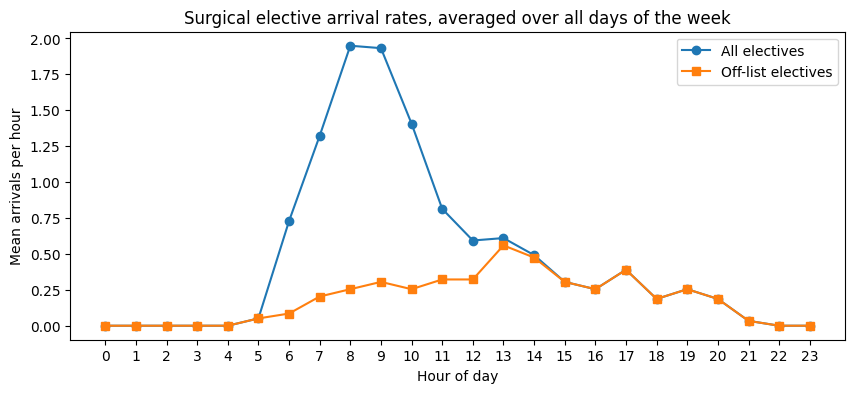

In [9]:
def hourly(rates_by_time):
    return np.array(list(rates_by_time.values())).reshape(24, intervals_per_hour).sum(axis=1)

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(range(24), hourly(surgical_weights['arrival_rates_dict']), marker='o', label='All electives')
ax.plot(range(24), hourly(surgical_weights['off_list_arrival_rates_dict']), marker='s', label='Off-list electives')
ax.set_xticks(range(24))
ax.set_xlabel('Hour of day')
ax.set_ylabel('Mean arrivals per hour')
ax.set_title('Surgical elective arrival rates, averaged over all days of the week')
ax.legend()
plt.show()

## Predict for one day

To make a prediction, the model needs three things in addition to the usual `prediction_time` and `prediction_window`:

* `day_list`: the list for the prediction date, including patients who may already have arrived. The same list can be passed for every service. Services without enough list data at fit, such as `paediatric` and `haem/onc` here, ignore it and give the Poisson-only result.
* `arrivals`: elective arrivals at all services. The model uses them to drop listed patients who have already arrived by the prediction time, at any service. They must include listed patients who arrived without needing a bed, because at the prediction time nobody knows yet which arrivals will need one. If those patients are left out, for example because only a feed of admissions is used, they stay on the pending list and the prediction is too high. Arrivals after the prediction time are ignored. This means that when predicting for a past day, as here, you can pass all the arrivals you have, and the prediction will not use any arrival that happened after the prediction time.
* `prediction_date`: the date, which anchors the prediction time and selects the arrival rates for that day of the week.

I use Monday 6 March 2023 from the test period. I chose it because its surgical list was shorter than usual for a Monday, which shows the difference the list makes.

In [10]:
prediction_date = date(2023, 3, 6)
prediction_window = timedelta(hours=8)
elective_list_for_day = elective_list[elective_list['intended_date'] == prediction_date]

print(f'Patients on the list for {prediction_date}: {len(elective_list_for_day)}')
elective_list_for_day['service'].value_counts()

Patients on the list for 2023-03-06: 14


service
surgical      12
paediatric     2
Name: count, dtype: int64

### Conditioning on not having arrived yet

At the prediction time, some listed patients have already arrived. The model drops them, and predicts only for those still pending.

`p_k` was estimated from everyone on the list at the start of the day. Summed over the window, it gives the probability that a patient taken from the whole list arrives in the window. The patients still pending are a different group. None of them has arrived yet, so a larger share of them will arrive later in the day. To get the probability for a pending patient, the model divides by the share of the list that is still pending at the prediction time:

```
q = sum of p_k over the part of the window on the day
    / (1 - sum of (p_k + r_k + s_k) from 00:00 to the prediction time)
```

`q` is the *conditioned probability*: the probability that a patient who is still pending arrives in the window. For example, if a third of everyone on the list arrives in the window, and half of the list is still pending at the prediction time, then a pending patient arrives in the window with probability (1/3) / (1/2) = 2/3. At 00:00 nobody has arrived, the denominator is 1, and the two probabilities are the same.

This only works if training and inference agree on who is still pending. At inference time, the model drops every listed patient who has arrived, at any service, because nobody knows yet which of them will need a bed. So the denominator counts every way a listed patient can already have arrived: needing a bed at the listed service (`p_k`), needing a bed at a different service (`r_k`), or not needing a bed (`s_k`).

If `s_k` were left out, which is what happens when the model is fitted without `arrivals_not_admitted`, training would treat patients who arrived without needing a bed as never having arrived. It would keep them in the pending pool all day, while inference drops them as they arrive. The pending share would be too high, so `q`, and the listed part of the prediction, would be too low. The opposite mistake, leaving those patients out of `arrivals` at inference time, keeps them on the pending list and makes the prediction too high.

The model does this calculation itself. The code below works it through for the surgical list at 09:30, and shows what `q` would be without `s_k`.

In [11]:
from datetime import datetime

# p_k, r_k and s_k for the surgical service: one value per 15-minute interval of the day
p_k = surgical_weights['list_interval_probs']
r_k = surgical_weights['list_other_service_probs']
s_k = surgical_weights['list_not_admitted_probs']

prediction_moment = datetime(2023, 3, 6, 9, 30)
start = int(timedelta(hours=9, minutes=30) / yta_time_interval)
end = start + int(prediction_window / yta_time_interval)

whole_list_prob = p_k[start:end].sum()
share_pending = 1 - (p_k[:start] + r_k[:start] + s_k[:start]).sum()
q = whole_list_prob / share_pending

surgical_list_for_day = elective_list_for_day[elective_list_for_day['service'] == 'surgical']
arrived = elective_arrivals.loc[elective_arrivals['arrival_datetime'] <= prediction_moment, 'encounter']
n_pending = (~surgical_list_for_day['encounter'].isin(arrived)).sum()

print(f'Probability of arriving in the window, for a patient from the whole list: {whole_list_prob:.2f}')
print(f'Share of the list still pending at 09:30: {share_pending:.2f}')
print(f'q = {whole_list_prob:.2f} / {share_pending:.2f} = {q:.2f}')
print(f'Listed part of the prediction: Binomial({n_pending}, {q:.2f})')

# Fitting without arrivals_not_admitted gives the same p_k and r_k, but no s_k
q_without_s_k = whole_list_prob / (share_pending + s_k[:start].sum())
print(f'q without s_k: {q_without_s_k:.2f}')

Probability of arriving in the window, for a patient from the whole list: 0.21
Share of the list still pending at 09:30: 0.53
q = 0.21 / 0.53 = 0.40
Listed part of the prediction: Binomial(8, 0.40)
q without s_k: 0.32


Conditioning nearly doubles the probability for each pending patient. Without `s_k`, `q` would be a fifth lower, and so would the expected number of listed arrivals.

### Off-list arrivals

Off-list electives have no known count, so they are modelled with a Poisson distribution, as in notebook 3e. Its mean is the off-list rates for that day of the week, summed over the window. (Windows that run past midnight are covered below.)

In [12]:
# Off-list rates for this day of the week: one value per 15-minute interval of the day
off_list_rates = list(surgical_weights['off_list_arrival_rates_by_weekday'][prediction_date.weekday()].values())
off_list_mean = sum(off_list_rates[start:end])

print(f'Off-list part of the prediction: Poisson({off_list_mean:.2f})')

Off-list part of the prediction: Poisson(2.11)


### Combining the two parts

The listed and off-list parts are independent, so the distribution of their total is the convolution of the two distributions. The code below builds each part, convolves them, and checks the result against `predict()`, which returns the full probability distribution.

Largest difference from predict(): 7.2e-09


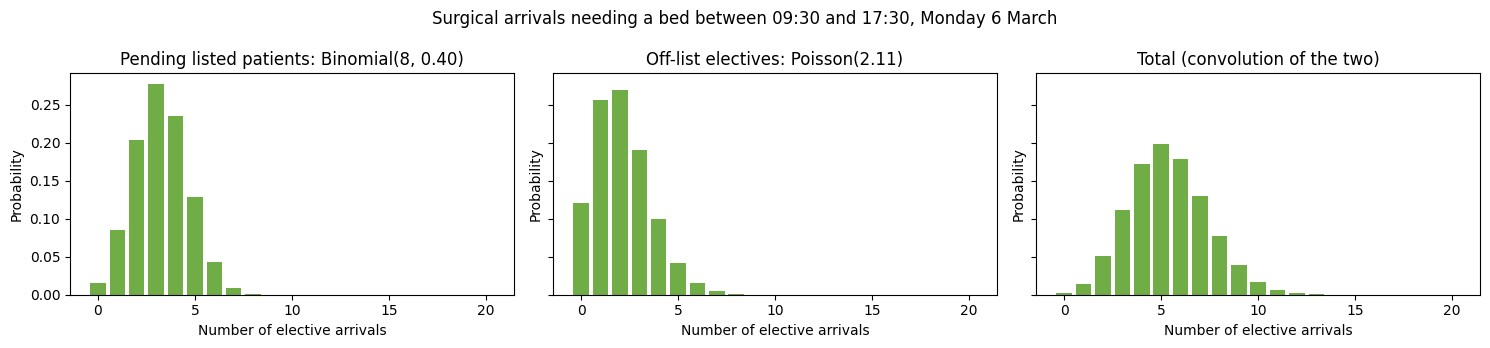

In [13]:
from scipy.stats import binom, poisson
from patientflow.viz.probability_distribution import plot_prob_dist
from patientflow.viz.pipeline_plots import create_colour_dict

colour_dict = create_colour_dict()

counts = np.arange(25)
listed_pmf = binom.pmf(counts, n_pending, q)
off_list_pmf = poisson.pmf(counts, off_list_mean)
combined_pmf = np.convolve(listed_pmf, off_list_pmf)

model_pmf = list_model.predict(
    prediction_time=(9, 30),
    prediction_window=prediction_window,
    filter_keys='surgical',
    prediction_date=prediction_date,
    day_list=elective_list_for_day,
    arrivals=elective_arrivals,
)['surgical']['agg_proba'].to_numpy()
n = min(len(combined_pmf), len(model_pmf))
print(f'Largest difference from predict(): {np.abs(combined_pmf[:n] - model_pmf[:n]).max():.1e}')

fig, axes = plt.subplots(1, 3, figsize=(15, 3.5), sharey=True)
for ax, pmf, title in zip(
    axes,
    [listed_pmf, off_list_pmf, combined_pmf],
    [f'Pending listed patients: Binomial({n_pending}, {q:.2f})',
     f'Off-list electives: Poisson({off_list_mean:.2f})',
     'Total (convolution of the two)'],
):
    plot_prob_dist(pmf, title, include_titles=True, truncate_at_beds=20,
                   bar_colour=colour_dict['single']['surgical'],
                   xlabel='Number of elective arrivals', ax=ax)
window_end = prediction_moment + prediction_window
fig.suptitle(f'Surgical arrivals needing a bed between {prediction_moment:%H:%M} and {window_end:%H:%M}, '
             f'{prediction_date:%A} {prediction_date.day} {prediction_date:%B}')
plt.tight_layout()
plt.show()

## Compare with the Poisson-only prediction

If no `day_list` is passed, the same fitted object gives exactly the result of `DirectAdmissionPredictor`, a Poisson distribution based on past arrival rates for that weekday. This is similar to the first approach in notebook 3e.

Below I compare the two predictions at 06:00, with the number of surgical electives who actually arrived in the window and needed a bed marked in red. On this day, the list was shorter than usual for a Monday. The list-based prediction reflects that, whereas the Poisson-only prediction expects a typical Monday.

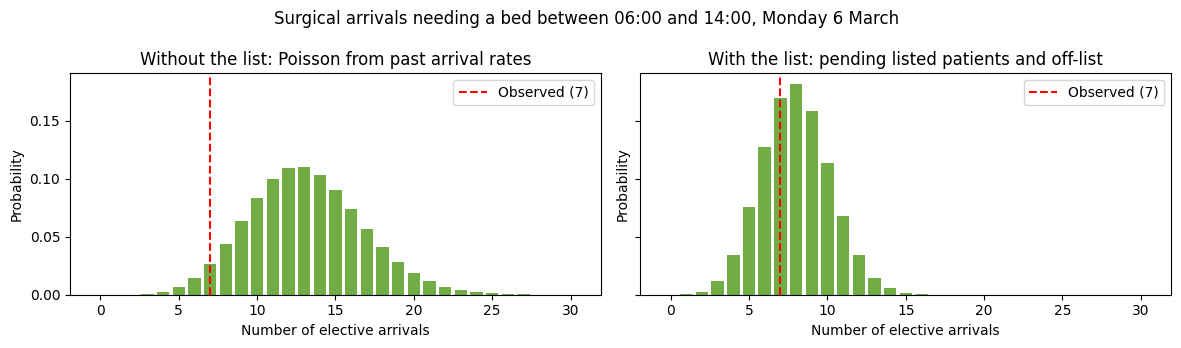

In [14]:
prediction_time = (6, 0)
# max_value sets the largest count in each distribution, so that neither is cut short
predict_args = dict(prediction_time=prediction_time, prediction_window=prediction_window,
                    filter_keys='surgical', prediction_date=prediction_date, max_value=60)

pmf_with_list = list_model.predict(day_list=elective_list_for_day, arrivals=elective_arrivals,
                                   **predict_args)['surgical']
pmf_without_list = list_model.predict(**predict_args)['surgical']

# Surgical electives who arrived in the window on this day and needed a bed
prediction_moment = datetime.combine(prediction_date, datetime.min.time()).replace(hour=6)
observed_arrivals = ((elective_arrivals['service'] == 'surgical')
                     & elective_arrivals['is_admitted']
                     & (elective_arrivals['arrival_datetime'] > prediction_moment)
                     & (elective_arrivals['arrival_datetime'] <= prediction_moment + prediction_window)).sum()

fig, axes = plt.subplots(1, 2, figsize=(12, 3.5), sharey=True)
for ax, pmf, label in zip(
    axes,
    [pmf_without_list, pmf_with_list],
    ['Without the list: Poisson from past arrival rates', 'With the list: pending listed patients and off-list'],
):
    plot_prob_dist(pmf, label, include_titles=True, truncate_at_beds=30,
                   bar_colour=colour_dict['single']['surgical'],
                   xlabel='Number of elective arrivals', ax=ax)
    ax.axvline(observed_arrivals, color='red', linestyle='--', label=f'Observed ({observed_arrivals})')
    ax.legend()
window_end = prediction_moment + prediction_window
fig.suptitle(f'Surgical arrivals needing a bed between {prediction_moment:%H:%M} and {window_end:%H:%M}, '
             f'{prediction_date:%A} {prediction_date.day} {prediction_date:%B}')
plt.tight_layout()
plt.show()

Using the list moves the prediction towards what happened on this day, and narrows it, because the size of the list is known rather than estimated.

This is one day, and the data is fake, so it is an illustration rather than an evaluation. Evaluating list-based predictions is not covered in these notebooks.

## Prediction windows that run past midnight

The list only covers the day it was made for. If the prediction window runs past midnight, the model assumes that no patient on today's list arrives after 24:00, so the list contributes nothing after midnight. Those hours are predicted from the all-elective rates for the next day of the week, because tomorrow's list is not yet known.

## Summary

Here I have shown how to use a list of planned admissions to predict elective demand with `ListBasedAdmissionPredictor`:

* At fit time, the model learns when listed patients arrive (`p_k`), how often they arrive at a different service (`r_k`) or without needing a bed (`s_k`), and the arrival rates of off-list electives.
* At inference time, it drops every listed patient who has already arrived, at any service, because it is not yet known which of them will need a bed. It predicts for those still pending. The probability for each pending patient is conditioned on them not having arrived yet.
* Training and inference must agree on who is still pending. Pass listed patients who arrived without needing a bed as `arrivals_not_admitted` at fit, and include the same patients in `arrivals` at inference time.
* The listed and off-list parts are combined into a single distribution. Because the number of listed patients is known rather than estimated from past days, this distribution is usually narrower than a Poisson-only prediction. How much the list helps depends on how closely it matches who actually arrives. A list on which many patients do not arrive, or a service with many off-list electives, gains less.
* Without a list, or for services with too few listed patients, the model gives exactly the Poisson-only result of `DirectAdmissionPredictor`.